<a href="https://colab.research.google.com/github/jorgecaraveobalderas-beep/Class-Files/blob/main/Ejercicios_sobre_Clases_No_Balanceadas%2C_Data_Leakage_(Pipeline)_y_SVM_274702_13_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ejercicios sobre Clases No Balanceadas, Data Leakage (Pipeline) y SVM
### Maestría en Inteligencia Artificial y Analítica de Datos
**Módulo:** Analítica Predictiva · Sesión 13_2

**Dataset:** Compustat

**Nombre:** Jorge Alberto Caraveo Balderas

**Matricula** 274702

---

## Contenido del Notebook

| Bloque | Tema |
|--------|------|
| 1 | Carga de Bibliotecas|
| 2 | Análisis Exploratorio de Datos (AED) |
| 3 | Modelo Base |
| 4 | Tratamiento de Clases No Balanceadas |
| 5 | Entrenamiento y Evaluación del Modelo|
| 6 | Evaluación de Resultados|
| 7 | Discusión y Conclusiones|

## Bloque 1 · Carga de Bibliotecas

- 1.-Declarar las bibliotecas necesarias para este proyecto
- 2.-Carga el dataset "Compustat"

Consideraciones importantes:

- El conjunto de datos contiene 21 atributos.
- El primer atributo corresponde a un índice, por lo que deberá ser ignorado durante el análisis y entrenamiento.
- El último atributo corresponde a la etiqueta de clase.
Los atributos restantes deberán utilizarse como variables predictoras.

In [1]:
# 1 - Declarar las bibliotecas necesarias para este proyecto
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from collections import Counter
from imblearn.combine import SMOTEENN
from imblearn.under_sampling import OneSidedSelection
from sklearn.model_selection import StratifiedKFold, cross_validate
from imblearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


#2 Carga el dataset "Compustat"
df = pd.read_csv('compustat.csv')

print(df.info())
print()
display(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13657 entries, 0 to 13656
Data columns (total 22 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   idx     13657 non-null  int64  
 1   at0     13657 non-null  float64
 2   at1     13657 non-null  float64
 3   at2     13657 non-null  float64
 4   at3     13657 non-null  float64
 5   at4     13657 non-null  float64
 6   at5     13657 non-null  float64
 7   at6     13657 non-null  float64
 8   at7     13657 non-null  float64
 9   at8     13657 non-null  float64
 10  at9     13657 non-null  float64
 11  at10    13657 non-null  float64
 12  at11    13657 non-null  float64
 13  at12    13657 non-null  float64
 14  at13    13657 non-null  float64
 15  at14    13657 non-null  float64
 16  at15    13657 non-null  float64
 17  at16    13657 non-null  float64
 18  at17    13657 non-null  float64
 19  at18    13657 non-null  float64
 20  at19    13657 non-null  float64
 21  label   13657 non-null  int64  
dty

,idx,at0,at1,at2,at3,at4,at5,at6,at7,at8,...,at11,at12,at13,at14,at15,at16,at17,at18,at19,label
0,0,0.076753,0.066548,0.132170,4.257882,0.771988,0.669344,0.076278,2.898450,6.081867,...,2.052378,0.372113,0.322636,0.250182,1.153351,0.451476,0.590680,0.512143,0.076278,0
1,1,0.097633,0.087736,0.162879,4.141787,0.781934,0.702665,0.082633,2.947445,6.272092,...,1.968984,0.371728,0.334043,0.231646,1.112813,0.409376,0.593143,0.533012,0.056273,0
2,2,0.025683,0.022020,0.152882,3.140505,0.698522,0.598883,0.097905,2.971928,6.508112,...,1.374306,0.305678,0.262075,0.220100,1.166375,0.487141,0.476098,0.408186,0.050251,0
3,3,0.011354,0.008987,0.165670,2.927575,0.699374,0.553558,0.107831,2.955952,6.588417,...,1.173407,0.280317,0.221873,0.245524,1.263416,0.487903,0.460482,0.364474,0.047244,0
4,4,0.001675,0.001212,0.155509,3.120983,0.689971,0.499122,0.098458,2.896668,6.607998,...,1.069792,0.236504,0.171086,0.271291,1.382369,0.464594,0.468896,0.339197,0.042986,0


### Conclusión - Bloque 1 · Carga de Bibliotecas

* **Notebook configurado:** Se importaron correctamente las librerias requeridas para la actividad
* **Dataset** El archivo Compustat contiene 13,657 instancias y 22 columnas, registrando cero valores nulos


## Bloque 2 . Análisis Exploratorio de Datos (AED)
- 1.-Un diagrama de barras mostrando la distribución de las clases.
- 2.-Diagramas de densidad KDE para los atributos 5 y 13.
- 3.-Un análisis breve sobre el nivel de desbalance presente en el conjunto de datos

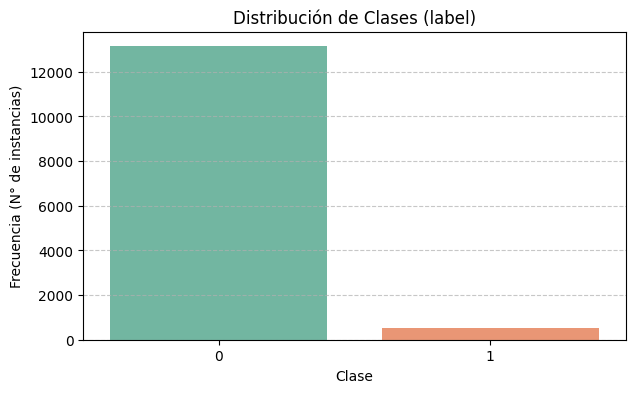

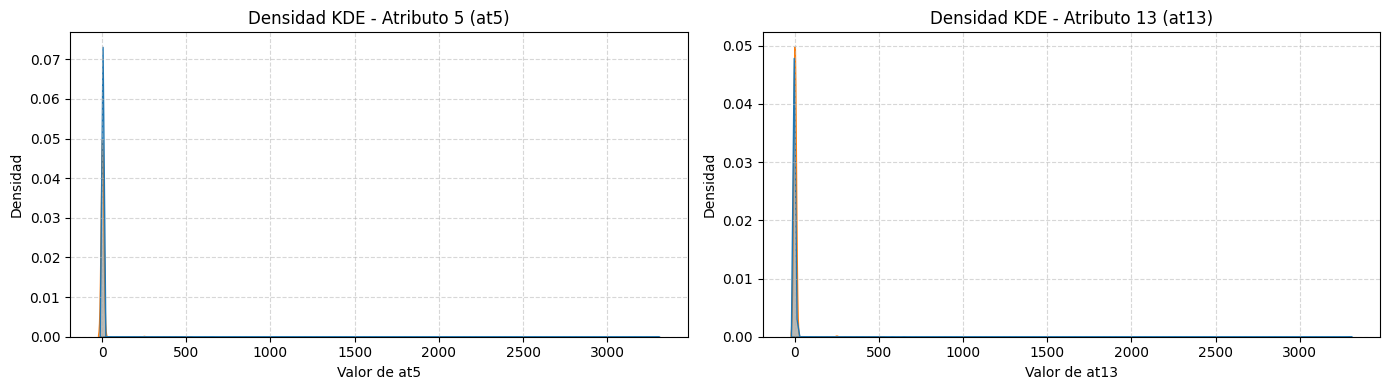

Analisis de desbalance de clases
Clase 0: 13,137 registros (96.19%)
Clase 1: 520 registros (3.81%)


In [2]:
# 1.-Un diagrama de barras mostrando la distribución de las clases.
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='label', hue='label', palette='Set2', legend=False)
plt.title('Distribución de Clases (label)')
plt.xlabel('Clase')
plt.ylabel('Frecuencia (N° de instancias)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# 2.-Diagramas de densidad KDE para los atributos 5 y 13.
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

#KDE para atributo 5
sns.kdeplot(data=df, x='at5', hue='label', common_norm=False, fill=True, alpha=0.3, ax=axes[0],legend=False)
axes[0].set_title('Densidad KDE - Atributo 5 (at5)')
axes[0].set_xlabel('Valor de at5')
axes[0].set_ylabel('Densidad')
axes[0].grid(True, linestyle='--', alpha=0.5)

#KDE para atributo 13
sns.kdeplot(data=df, x='at13', hue='label', common_norm=False, fill=True, alpha=0.3, ax=axes[1],legend=False)
axes[1].set_title('Densidad KDE - Atributo 13 (at13)')
axes[1].set_xlabel('Valor de at13')
axes[1].set_ylabel('Densidad')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# 3.-Un análisis breve sobre el nivel de desbalance presente en el conjunto de datos
conteo_clases = df['label'].value_counts()
porcentaje_clases = df['label'].value_counts(normalize=True) * 100

print("Analisis de desbalance de clases")
for clase in conteo_clases.index:
    print(f"Clase {clase}: {conteo_clases[clase]:,} registros ({porcentaje_clases[clase]:.2f}%)")

### Conclusion - Bloque 2 Análisis Exploratorio de Datos (AED)

* **Desbalance de clases:** El conjunto presenta una marcada asimetría en la variable objetivo (`label`), donde la Clase 0 agrupa 13,137 registros (96.19%) y la Clase 1 únicamente 520 registros (3.81%), representando una proporción aproximada de 25 a 1
* **Comportamiento y sesgo en `at5` y `at13`:** Los diagramas KDE muestran que ambas variables concentran casi toda su densidad cerca de cero, pero tienen colas largas hacia la derecha con valores atípicos superiores a 3,000
* **Implicaciones para el modelado:** Debido al desbalance del 96.19% vs. 3.81%, evaluar el modelo solo con accuracy sería engañoso. Es importante considerar particiones estratificadas


## Bloque 3 . Modelo Base

- 1.-Entrenar un modelo baseline utilizando:

Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))
])

Este modelo deberá entrenarse sin aplicar métodos de tratamiento de desbalance y servirá como referencia para comparar los resultados posteriores.

Reporte de clasificacion
              precision    recall  f1-score   support

           0     0.9623    1.0000    0.9808      2628
           1     1.0000    0.0096    0.0190       104

    accuracy                         0.9623      2732
   macro avg     0.9811    0.5048    0.4999      2732
weighted avg     0.9637    0.9623    0.9442      2732



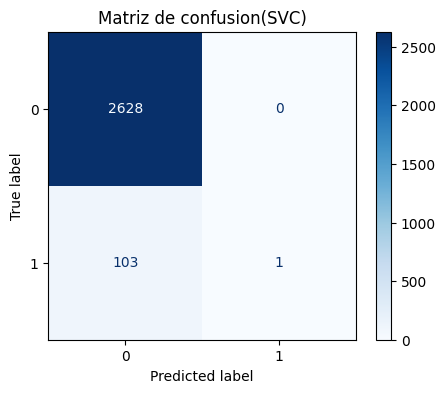

In [3]:
# 1.-Separar variables predictoras (X) y variable objetivo (y). Se descarta 'idx' y 'label' como variable predictora (En base las instrucciones del Bloque 1)
X = df.drop(columns=['idx', 'label'])
y = df['label']

# 2.-Particion en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3.-Definicion y entrenamiento del Pipeline baseline
baseline_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))
])

baseline_pipeline.fit(X_train, y_train)
y_pred = baseline_pipeline.predict(X_test)

print("Reporte de clasificacion")
print(classification_report(y_test, y_pred, digits=4))

# 5.-Visualizacion de la matriz de confusion
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues', ax=ax)
plt.title('Matriz de confusion(SVC)')
plt.show()

### Conclusion - Bloque 3 Modelo Base

* **Ilusión de alta exactitud:** El modelo baseline alcanzó un accuracy global del 96.23, cifra que resulta engañosa debido al desbalance extremo: el clasificador aprende a predecir casi exclusivamente la clase mayoritaria para minimizar el error global
* **Falla en la clase de interés (Clase 1):** De las 104 instancias reales de la clase 1 en el conjunto de prueba, el modelo únicamente identificó 1 caso correcto y clasificó erróneamente 103 casos como Clase 0 (falsos negativos), arrojando un Recall de apenas 0.96% y un F1-score de 0.0190
* **Línea base para bloques posteriores:** Este resultado demuestra cuantitativamente por qué un modelo estándar sin tratamiento de desbalance no funciona para la detección de eventos aislados

## Bloque 4 . Tratamiento de Clases No Balanceadas

1.- Aplicar y comparar los siguientes métodos:

- SMOTEENN
- One-Sided Selection

2.- Para cada método:

- Mostrar la nueva distribución de clases después del balanceo.
- Entrenar nuevamente el modelo SVM utilizando los datos balanceados.

Distribucion original en entrenamiento:
Counter({0: 10509, 1: 416})
Nueva distribucion con SMOTEENN:
Counter({1: 10434, 0: 9395})
Reporte de clasificacion SMOTEENN
              precision    recall  f1-score   support

           0     0.9930    0.8071    0.8904      2628
           1     0.1493    0.8558    0.2543       104

    accuracy                         0.8089      2732
   macro avg     0.5712    0.8314    0.5724      2732
weighted avg     0.9609    0.8089    0.8662      2732



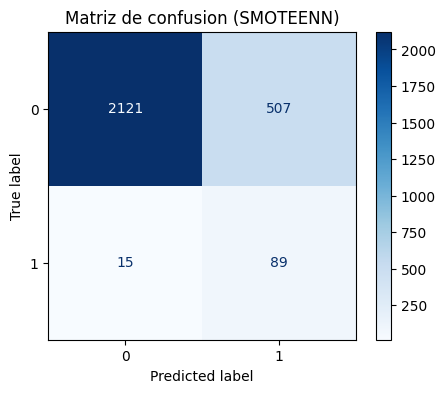

Nueva distribucion con One-Sided Selection:
Counter({0: 10222, 1: 416})
Reporte de clasificacion One-Sided Selection
              precision    recall  f1-score   support

           0     0.9623    1.0000    0.9808      2628
           1     1.0000    0.0096    0.0190       104

    accuracy                         0.9623      2732
   macro avg     0.9811    0.5048    0.4999      2732
weighted avg     0.9637    0.9623    0.9442      2732



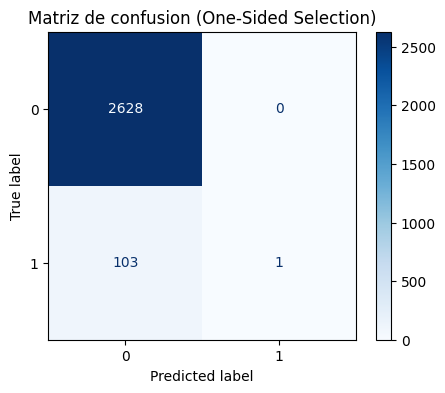

In [4]:
# 1.-Aplicar SMOTEENN y mostrar distribucion de clases después del balanceo
smoteenn = SMOTEENN(random_state=42)
X_train_sme, y_train_sme = smoteenn.fit_resample(X_train, y_train)

print("Distribucion original en entrenamiento:")
print(Counter(y_train))
print("Nueva distribucion con SMOTEENN:")
print(Counter(y_train_sme))

# 2.-Entrenar nuevamente el modelo SVM utilizando los datos balanceados
pipeline_sme = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))
])

pipeline_sme.fit(X_train_sme, y_train_sme)
y_pred_sme = pipeline_sme.predict(X_test)

print("Reporte de clasificacion SMOTEENN")
print(classification_report(y_test, y_pred_sme, digits=4))

# 3.-Visualizacion de la matriz de confusion SMOTEENN
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_sme, cmap='Blues', ax=ax)
plt.title('Matriz de confusion (SMOTEENN)')
plt.show()

# 4.-Aplicar One-Sided Selection y mostrar distribucion de clases después del balanceo
oss = OneSidedSelection(random_state=42)
X_train_oss, y_train_oss = oss.fit_resample(X_train, y_train)

print("Nueva distribucion con One-Sided Selection:")
print(Counter(y_train_oss))

# 5.-Entrenar y evaluar SVM con One-Sided Selection utilizando los datos balanceados
pipeline_oss = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))
])

pipeline_oss.fit(X_train_oss, y_train_oss)
y_pred_oss = pipeline_oss.predict(X_test)

print("Reporte de clasificacion One-Sided Selection")
print(classification_report(y_test, y_pred_oss, digits=4))

# 6.-Visualizacion de la matriz de confusion One-Sided Selection
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_oss, cmap='Blues', ax=ax)
plt.title('Matriz de confusion (One-Sided Selection)')
plt.show()

### Conclusion - Bloque 4 Tratamiento de Clases No Balanceadas

* **Efectividad de SMOTEENN:** La combinación de muestreo sintético y limpieza de ruido en fronteras transformó la distribución de entrenamiento a 10,434 (Clase 1) vs. 9,395 (Clase 0). Esto permitió al SVM desplazar su frontera de decisión, elevando el Recall de la Clase 1 del 0.96% al 85.58%
* **Costo en precisión con SMOTEENN:** Los falsos positivos aumentaron a 507, reduciendo la precisión de la Clase 1 al 14.93%, pero alcanzando un F1-score*de 0.2543
* **Ineficacia de One-Sided Selection:** El submuestreo únicamente eliminó 287 instancias ruidosas de la Clase 0 (pasando de 10,509 a 10,222), manteniendo intacta la Clase 1 con 416 registros. Al persistir un desbalance, el modelo replicó exactamente el fallo del baseline Recall de 0.96
* **Conclusión comparativa:** SMOTEENN demostró ser el método adecuado para este conjunto de datos, logrando que el modelo aprenda los patrones de la clase minoritaria, mientras que One-Sided resultó insuficiente por sí solo al no corregir la disparidad de volumen entre clases

## Bloque 5 . Entrenamiento y Evaluación del Modelo

- 1.-Utilizar validación cruzada estratificada de 5 particiones.
- 2.-Implementar el flujo de trabajo utilizando Pipeline para evitar data leakage.
- 3.-Incorporar escalado de datos dentro del Pipeline.
- 4.-Utilizar SVM con kernel RBF.

In [7]:
# 1.-Utilizar validación cruzada estratificada de 5 particiones.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 2 - 4.-Implementar el flujo de trabajo utilizando Pipeline para evitar data leakage / Incorporar escalado de datos dentro del Pipeline / Utilizar SVM con kernel RBF
model_pipeline = Pipeline([
    ('smoteenn', SMOTEENN(random_state=42)),
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))
])
metricas = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
scores = cross_validate(model_pipeline, X, y, cv=cv, scoring=metricas, n_jobs=-1)
print("Resultados de Validacion Cruzada Estratificada (5 folds):")
for metrica in metricas:
    media = np.mean(scores[f'test_{metrica}'])
    desv = np.std(scores[f'test_{metrica}'])
    print(f"{metrica.capitalize()}: {media:.4f} (+/- {desv:.4f})")

Resultados de Validacion Cruzada Estratificada (5 folds):
Accuracy: 0.8120 (+/- 0.0067)
Precision: 0.1449 (+/- 0.0095)
Recall: 0.8038 (+/- 0.0582)
F1: 0.2456 (+/- 0.0161)
Roc_auc: 0.8859 (+/- 0.0130)


### Conclusion - Bloque 5 Entrenamiento y Evaluación del Modelo

* **Prevención efectiva de fuga de datos:** La integración de `SMOTEENN` y `StandardScaler` dentro de `imblearn.pipeline.Pipeline` aseguró que tanto la generación sintética de instancias como el cálculo de media y desviación estándar se ejecutaran solo en el subconjunto de entrenamiento de cada una de las 5 particiones, garantizando una evaluación rigurosa
* **Consistencia y alta sensibilidad en la clase minoritaria:** El modelo demostró una capacidad de generalización al promediar un recall de 80.38% (± 5.82%) confirmando que la sensibilidad lograda por SMOTEENN se mantiene estable en datos no vistos
* **Capacidad discriminatoria global:** El clasificador alcanzó un ROC-AUC de 0.8859 (± 1.30%), lo que indica que el SVM RBF separa eficientemente las distribuciones de probabilidad entre ambas clases
* **Estabilidad:** El modelo exhibió una estabilidad en su accuracy (81.20% ± 0.67%) y F1-score (0.2456 ± 1.61%). Aunque la precisión se situó en 14.49% (± 0.95%)debido a los falsos positivos del balanceo

## Bloque 6 . Evaluación de Resultados

1.-Reportar y analizar al menos las siguientes métricas:

- Accuracy
- Precision
- Recall
- F1-score
- Matriz de confusión

2.-Además:

- Comparar los resultados del modelo baseline contra los modelos balanceados.
- Generar una gráfica comparativa de métricas.
- Analizar si Accuracy es suficiente para evaluar el problema.

Tabla comparativa de metricas:


,Accuracy,Precision,Recall,F1-score
Modelo,,,,
Baseline,0.9623,1.0000,0.0096,0.0190
One-Sided Selection,0.9623,1.0000,0.0096,0.0190
SMOTEENN,0.8089,0.1493,0.8558,0.2543


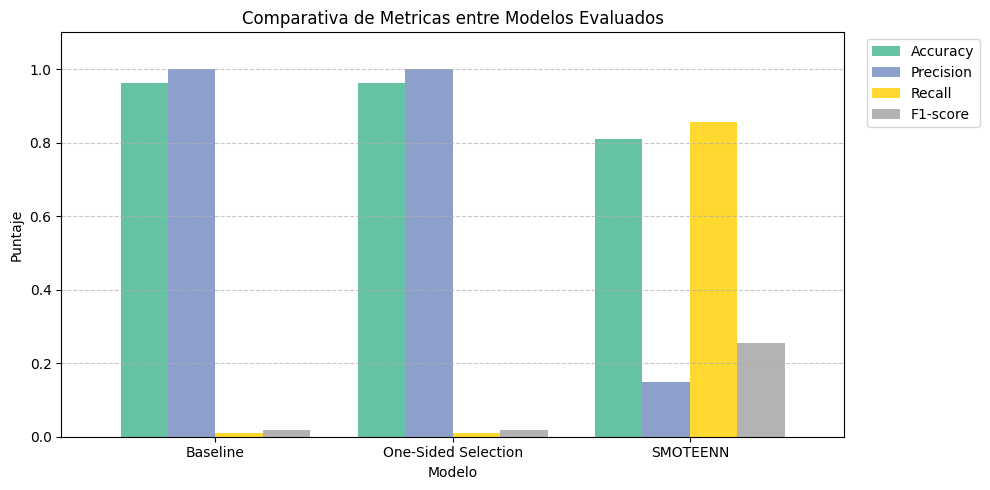

In [6]:
# 1.-Reportar y analizar al menos las siguientes métricas (Accuracy, Precision, Recall, F1-score, matriz de confusión)
modelos = {
    'Baseline': y_pred,
    'One-Sided Selection': y_pred_oss,
    'SMOTEENN': y_pred_sme
}

metricas_lista = []
for nombre, preds in modelos.items():
    metricas_lista.append({
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds, pos_label=1),
        'Recall': recall_score(y_test, preds, pos_label=1),
        'F1-score': f1_score(y_test, preds, pos_label=1)
    })

df_comparativa = pd.DataFrame(metricas_lista).set_index('Modelo')
print("Tabla comparativa de metricas:")
display(df_comparativa.round(4))

# 2.-Generar una gráfica comparativa de métricas y analizar si Accuracy es suficiente para evaluar el problema.
ax = df_comparativa.plot(kind='bar', figsize=(10, 5), colormap='Set2', width=0.8)
plt.title('Comparativa de Metricas entre Modelos Evaluados')
plt.xlabel('Modelo')
plt.ylabel('Puntaje')
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Conclusión - Bloque 6 · Evaluación de Resultados

* **Comparación visual y cuantitativa entre modelos:**
* **Baseline y One-Sided Selection:** Presentan un comportamiento idéntico en la gráfica (accuracy de 0.9623 y precision de 1.0000) esta precisión perfecta es un engañoso ya que cuenta con un recall crítico de apenas 0.0096 y un F1-score de 0.0190
* **SMOTEENN:** Es el único modelo que logró arreglar el desbalance. Como ilustra la barra amarilla, incrementó el Recall a 0.8558 y elevó el F1-score a 0.2543, consolidándose como la solución efectiva

* **Insuficiencia del Accuracy:** La gráfica comprueba que el accuracy no es una métrica correcta para seleccionar el modelo. Tanto el baseline como OSS obtuvieron la exactitud más alta (96.23%) ignorando a la clase minoritaria. Un modelo que acierta el 96% de las veces favoreciendo unicamente a la clase mayoritaria

## Bloque 7 . Discusión y Conclusiones

- El impacto del desbalance sobre el desempeño del modelo.
- Las diferencias observadas entre SMOTEENN y One-Sided Selection.
- Qué método produjo los mejores resultados y por qué.

### Conclusion - Bloque 7 Discusión y Conclusiones

* **Impacto del desbalance sobre el desempeño del modelo:**
  * La presencia de un desbalance severo provocó la paradoja del accuracy en el modelo baseline.
  * El clasificador optimizó la función de pérdida asignando casi todas las instancias a la clase mayoritaria, alcanzando un Accuracy engañoso de 96.23%, pero fallando en detectar el 99.04% de los casos críticos
  * Esto demuestra que, en ausencia de técnicas de mitigación, los clasificadores basados en márgenes como SVM quedan totalmente sesgados hacia la clase dominante y resultan no utilizables

* **Diferencias observadas entre SMOTEENN y One-Sided Selection:**
  Únicamente removió 287 instancias de frontera de la clase mayoritaria en entrenamiento (pasando de 10,509 a 10,222), manteniendo intactas las 416 instancias minoritarias. Al no alterar la disparidad sustancial de volumen, el SVM no modificó su frontera de decisión y replicó exactamente el fracaso del baseline (recall de 0.0096 y F1 de 0.0190)
  * **SMOTEENN:** Combinó la generación de ejemplos sintéticos con la depuración de instancias solapadas mediante vecinos más cercanos (ENN), equilibrando el entrenamiento a 10,434 (Clase 1) vs. 9,395 (Clase 0). Esta reconfiguración permitió al SVM trazar un hiperplano sensible a la clase minoritaria

* **Método superior y justificación analítica:**
  * **SMOTEENN produjo los mejores resultados:** Elevó el Recall en el conjunto de prueba de 0.96% a 85.58%, reduciendo las omisiones de 103 a solo 15, y logrando un F1-score de 0.2543 frente al 0.0190 de sus contrapartes
  * **Validación cruzada robusta:** El flujo implementado mediante `Pipeline` demostró la consistencia del método sin fuga de datos, sosteniendo en 5 particiones un recall promedio de 80.38% (± 5.82%) y un ROC-AUC de 0.8859 (± 1.30%), lo que confirma una capacidad de separación sólida y estable en datos no vistos